# Итоговый проект: гибридная система рекомендаций книг с нейросетевой моделью

Продолжение ДЗ №1 (`book_recommender.ipynb`, датасет Goodbooks-10k). Здесь базовые модели
(Popularity, Content TF-IDF, Item-Based CF, SVD) переиспользуются, а поверх них строится
гибридная система и нейросетевая Two-Tower модель.

**Структура:**
1. Подготовка: данные, сплит, обучение базовых моделей
2. Этап 1 — расширенные признаки (пользователи, книги, взаимодействия)
3. Этап 2 — гибридная система (взвешивание, сегменты, пул кандидатов, MMR)
4. Этап 3 — оценка, подбор весов, анализ по сегментам
5. Продвинутая часть — Two-Tower нейросеть, интеграция в гибрид
6. Сквозной пайплайн и выводы

## 1. Подготовка: данные и базовые модели из ДЗ №1

Повторяем подготовку из первого задания: загрузка, сплит 80/20 по пользователю,
обучение Popularity / Item-Based CF / SVD, TF-IDF-профили книг.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from surprise import Dataset, Reader, SVD, accuracy

warnings.filterwarnings('ignore')
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
%matplotlib inline

DATA = 'data/'
ratings = pd.read_csv(DATA + 'ratings.csv')
books = pd.read_csv(DATA + 'books.csv')
tags = pd.read_csv(DATA + 'tags.csv')
book_tags = pd.read_csv(DATA + 'book_tags.csv')

# ratings.book_id соответствует books.id (1..10000),
# а book_tags.goodreads_book_id — books.book_id. Приводим к понятным именам:
books = books.rename(columns={'id': 'book_id', 'book_id': 'goodreads_book_id'})

def train_test_split_by_user(ratings, test_frac=0.2, min_ratings=5, seed=42):
    rng = np.random.RandomState(seed)
    train_parts, test_parts = [], []
    for _, grp in ratings.groupby('user_id'):
        if len(grp) < min_ratings:
            train_parts.append(grp)
            continue
        n_test = max(1, int(round(len(grp) * test_frac)))
        test_idx = rng.choice(grp.index.values, size=n_test, replace=False)
        mask = grp.index.isin(test_idx)
        test_parts.append(grp[mask])
        train_parts.append(grp[~mask])
    return pd.concat(train_parts).sort_index(), pd.concat(test_parts).sort_index()

train, test = train_test_split_by_user(ratings)
print(f'train: {len(train):,} | test: {len(test):,}')

user_ids = np.sort(train['user_id'].unique())
book_ids = np.sort(train['book_id'].unique())
uid_map = {u: i for i, u in enumerate(user_ids)}
bid_map = {b: i for i, b in enumerate(book_ids)}
N_USERS, N_BOOKS = len(user_ids), len(book_ids)

R = sparse.csr_matrix(
    (train['rating'].astype(np.float32).values,
     (train['user_id'].map(uid_map).values, train['book_id'].map(bid_map).values)),
    shape=(N_USERS, N_BOOKS))
R_bin = R.copy()
R_bin.data = (R_bin.data >= 4).astype(np.float32)  # неявный фидбэк: 1 если оценка >= 4
R_bin.eliminate_zeros()
print(f'Матрица: {R.shape}, положительных взаимодействий: {R_bin.nnz:,}')

train: 795,729 | test: 186,027


Матрица: (53424, 10000), положительных взаимодействий: 526,628


In [2]:
# --- Popularity ---
MIN_RATINGS = 50
pop_stats = train.groupby('book_id').rating.agg(['mean', 'size'])
pop_vec = np.zeros(N_BOOKS, dtype=np.float32)
pop_vec[:] = pop_stats['mean'].reindex(book_ids).fillna(0).values
pop_vec[pop_stats['size'].reindex(book_ids).fillna(0).values < MIN_RATINGS] = 0

# --- Item-Based CF ---
K_NEIGHBORS = 30
S = cosine_similarity(R.T, dense_output=False)
S.setdiag(0); S.eliminate_zeros()

def keep_topk(S, k):
    S = S.tocsr()
    rows, cols, vals = [], [], []
    for i in range(S.shape[0]):
        s, e = S.indptr[i], S.indptr[i + 1]
        d, idx = S.data[s:e], S.indices[s:e]
        if len(d) > k:
            part = np.argpartition(d, -k)[-k:]
            d, idx = d[part], idx[part]
        rows.extend([i] * len(d)); cols.extend(idx); vals.extend(d)
    return sparse.csr_matrix((vals, (rows, cols)), shape=S.shape)

Sk = keep_topk(S, K_NEIGHBORS)
Sk_abs = Sk.copy(); Sk_abs.data = np.abs(Sk_abs.data)
del S

# --- SVD ---
reader = Reader(rating_scale=(1, 5))
trainset = Dataset.load_from_df(train[['user_id', 'book_id', 'rating']], reader).build_full_trainset()
testset = list(test[['user_id', 'book_id', 'rating']].itertuples(index=False, name=None))
svd = SVD(n_factors=50, n_epochs=15, lr_all=0.005, reg_all=0.02, random_state=42)
t0 = time.time()
svd.fit(trainset)
print(f'SVD обучена за {time.time() - t0:.0f} с')
rmse_svd = accuracy.rmse(svd.test(testset), verbose=False)
print(f'RMSE SVD: {rmse_svd:.4f}')

# маппинг «наш внутренний индекс книги» <-> «внутренний индекс surprise»
svd_iid_per_book = np.array([svd.trainset.to_inner_iid(int(b)) for b in book_ids])
bi_all = svd.bi[svd_iid_per_book]
qi_all = svd.qi[svd_iid_per_book]
mu = svd.trainset.global_mean

# --- Content TF-IDF ---
book_tag_str = (book_tags.merge(tags, on='tag_id')
                .groupby('goodreads_book_id')['tag_name'].apply(lambda s: ' '.join(s)))
books_content = books[['book_id', 'goodreads_book_id', 'original_title', 'authors']].copy()
books_content['tags_str'] = books_content['goodreads_book_id'].map(book_tag_str).fillna('')
books_content['profile'] = books_content['original_title'].fillna('') + ' ' + books_content['tags_str']
tfidf = TfidfVectorizer(max_features=50_000, min_df=2)
tfidf_matrix = tfidf.fit_transform(books_content['profile'])
bookid_to_row = {b: i for i, b in enumerate(books_content['book_id'])}
# строки TF-IDF в порядке наших внутренних индексов книг;
# часть book_id из оценок отсутствует в books.csv — даём им пустой профиль
missing_meta = [int(b) for b in book_ids if int(b) not in bookid_to_row]
print(f'Книг без метаданных в books.csv: {len(missing_meta)}')
order = [bookid_to_row.get(int(b)) for b in book_ids]
tfidf_inner = sparse.vstack([
    tfidf_matrix[i] if i is not None
    else sparse.csr_matrix((1, tfidf_matrix.shape[1]), dtype=np.float32)
    for i in order]).tocsr()
print('Базовые модели готовы.')

SVD обучена за 13 с


RMSE SVD: 0.8383


Книг без метаданных в books.csv: 0


Базовые модели готовы.


## Этап 1. Расширенные признаки

- **Пользователи:** число оценок, средний и стд рейтинга, доля высоких оценок, сегмент активности.
- **Книги:** популярность (число оценок), средний рейтинг, разнообразие оценок (стд),
  тематические категории (топ-тег книги).
- **Взаимодействия:** контентная схожесть кандидата с историей пользователя —
  профиль пользователя = средний TF-IDF-вектор книг, которые он оценил на ≥ 4.

In [3]:
# признаки пользователей
user_features = (train.groupby('user_id').rating
                 .agg(n_ratings='size', mean_rating='mean', std_rating='std',
                      high_share=lambda s: (s >= 4).mean()))
user_features['segment'] = np.where(user_features['n_ratings'] < 20, 'новый/малоданный', 'активный')
print('Признаки пользователей:')
display(user_features.head())

# признаки книг
top_tag = (book_tags.merge(tags, on='tag_id')
           .sort_values('count', ascending=False)
           .drop_duplicates('goodreads_book_id')
           .set_index('goodreads_book_id')['tag_name'])
book_features = (train.groupby('book_id').rating
                 .agg(n_ratings='size', mean_rating='mean', std_rating='std'))
book_features['main_tag'] = books.set_index('book_id')['goodreads_book_id'].map(top_tag).reindex(book_features.index).values
print('Признаки книг:')
display(book_features.head())

# контентные профили пользователей (признак «схожесть с историей»)
row_norm = np.asarray(R_bin.sum(axis=1)).ravel()
row_norm[row_norm == 0] = 1
R_bin_norm = sparse.diags(1.0 / row_norm) @ R_bin  # усреднение по лайкнутым книгам
print('Профили пользователей будут считаться как R_bin_norm @ tfidf_inner')

Признаки пользователей:


,n_ratings,mean_rating,std_rating,high_share,segment
user_id,,,,,
1,3,3.666667,0.577350,0.666667,новый/малоданный
2,3,4.333333,0.577350,1.000000,новый/малоданный
3,2,1.000000,0.000000,0.000000,новый/малоданный
4,3,4.000000,1.732051,0.666667,новый/малоданный
5,4,4.250000,0.957427,0.750000,новый/малоданный


Признаки книг:


,n_ratings,mean_rating,std_rating,main_tag
book_id,,,,
1,77,4.259740,0.833550,favorites
2,77,4.233766,0.971923,to-read
3,76,3.157895,1.497132,young-adult
4,81,4.444444,0.866025,classics
5,78,3.897436,1.051773,classics


Профили пользователей будут считаться как R_bin_norm @ tfidf_inner


## Этап 2. Гибридная система

**Архитектура:**
1. **Генерация кандидатов:** топ-50 от каждой модели (Popularity, Content, ItemCF, SVD) → общий пул;
   уже оценённые книги отфильтровываются.
2. **Взвешенное ранжирование:** скоры моделей нормируются min-max внутри пула кандидатов,
  итоговый скор = Σ wᵢ · scoreᵢ. Веса зависят от сегмента пользователя (новый/активный).
3. **MMR-переранжирование:** баланс релевантности и разнообразия — штрафуем кандидатов,
  похожих на уже выбранных (косинусная близость по TF-IDF).

In [4]:
CAND_PER_MODEL = 50

def itemcf_scores(u):
    ru = R[uid_map[u]]
    num = (Sk @ ru.T).toarray().ravel()
    den = (Sk_abs @ (ru > 0).T.astype(np.float32)).toarray().ravel()
    return np.divide(num, den, out=np.zeros_like(num), where=den > 0)

def svd_scores(u):
    iu = svd.trainset.to_inner_uid(u)
    return mu + svd.bu[iu] + bi_all + qi_all @ svd.pu[iu]

def candidates_and_scores(u, content_vec):
    """Пул кандидатов + нормированные скоры всех моделей для пользователя."""
    seen = R[uid_map[u]].indices
    raw = {'pop': pop_vec, 'itemcf': itemcf_scores(u), 'svd': svd_scores(u), 'content': content_vec}
    pool = set()
    for sc in raw.values():
        sc = sc.copy(); sc[seen] = -np.inf
        pool.update(np.argpartition(sc, -CAND_PER_MODEL)[-CAND_PER_MODEL:])
    pool = np.array(sorted(pool))
    pool = pool[~np.isin(pool, seen)]
    normed = {}
    for name, sc in raw.items():
        v = sc[pool].astype(np.float64)
        lo, hi = v.min(), v.max()
        normed[name] = (v - lo) / (hi - lo) if hi > lo else np.zeros_like(v)
    return pool, normed

def hybrid_rank(pool, normed, weights):
    score = sum(weights.get(m, 0.0) * normed[m] for m in normed)
    return score

def mmr_rerank(pool, score, n=10, lam=0.7):
    """Maximal Marginal Relevance: релевантность минус схожесть с уже выбранными."""
    vecs = tfidf_inner[pool]
    sim = (vecs @ vecs.T).toarray()
    selected, remaining = [], list(range(len(pool)))
    for _ in range(min(n, len(pool))):
        if not selected:
            i = int(np.argmax(score))
        else:
            mmr = lam * score[remaining] - (1 - lam) * sim[np.ix_(remaining, selected)].max(axis=1)
            i = remaining[int(np.argmax(mmr))]
        selected.append(i)
        remaining.remove(i)
    return pool[selected]

def recommend_hybrid(u, weights, n=10, lam=0.7, content_vec=None):
    if content_vec is None:
        content_vec = (R_bin_norm[uid_map[u]] @ tfidf_inner @ tfidf_inner.T).toarray().ravel()
    pool, normed = candidates_and_scores(u, content_vec)
    score = hybrid_rank(pool, normed, weights)
    top_inner = mmr_rerank(pool, score, n, lam)
    out = pd.DataFrame({'book_id': book_ids[top_inner]})
    return out.merge(books[['book_id', 'original_title', 'authors']], on='book_id')

demo_user = int(user_ids[100])
weights_demo = {'pop': 0.1, 'content': 0.2, 'itemcf': 0.4, 'svd': 0.3}
print(f'Гибридные рекомендации для пользователя {demo_user}:')
recommend_hybrid(demo_user, weights_demo)

Гибридные рекомендации для пользователя 101:


,book_id,original_title,authors
0,9933,Parts,Tedd Arnold
1,2445,The Beekeeper's Apprentice,Laurie R. King
2,1370,NaN,Alison Bechdel
3,9024,Angels in America: A Gay Fantasia on National...,Tony Kushner
4,8648,I Love You Through And Through,"Bernadette Rossetti-Shustak, Caroline Jayne Ch..."
5,7855,Murder Must Advertise,Dorothy L. Sayers
6,4947,Knuffle Bunny Too: A Case of Mistaken Identity,Mo Willems
7,8858,The Mermaids Singing,Val McDermid
8,7978,The Mapping of Love and Death,Jacqueline Winspear
9,8331,A Dog's Life: Autobiography of a Stray,Ann M. Martin


## Этап 3. Оценка и оптимизация

- Те же метрики, что в ДЗ №1: Precision@10 / Recall@10 / nDCG@10, релевантность = оценка ≥ 4 в тесте.
- Пользователи оценки делятся на **валидацию** (подбор весов) и **тест** (финальные цифры) —
  веса не подгоняются под тест.
- Подбор весов — отдельно для сегментов «новый/малоданный» (< 20 оценок) и «активный».

In [5]:
K_EVAL = 10
N_EVAL = 1500

def precision_recall_ndcg(recs, relevant, k):
    recs = list(recs)[:k]
    hits = sum(1 for b in recs if b in relevant)
    dcg = sum(1.0 / np.log2(i + 2) for i, b in enumerate(recs) if b in relevant)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return hits / k, hits / len(relevant) if relevant else 0.0, dcg / idcg if idcg else 0.0

relevant_by_user = test[test.rating >= 4].groupby('user_id')['book_id'].apply(set)
eval_users = np.array([u for u in relevant_by_user.index if u in uid_map])
eval_users = np.random.RandomState(0).permutation(eval_users)[:N_EVAL]
val_users, test_users = eval_users[:N_EVAL // 2], eval_users[N_EVAL // 2:]
print(f'val: {len(val_users)}, test: {len(test_users)}')

# контентные скоры для всех eval-пользователей одним матричным умножением
eval_inner = [uid_map[u] for u in eval_users]
content_eval = (R_bin_norm[eval_inner] @ tfidf_inner @ tfidf_inner.T).toarray().astype(np.float32)
print('content_eval:', content_eval.shape)

val: 750, test: 750


content_eval: (1500, 10000)


In [6]:
# предрасчёт пулов и скоров (один проход, дальше подбор весов — дешёвый)
t0 = time.time()
cache = {}
for u, cv in zip(eval_users, content_eval):
    pool, normed = candidates_and_scores(u, cv)
    cache[u] = (pool, normed)
print(f'Пулы кандидатов рассчитаны за {time.time() - t0:.0f} с')

def evaluate(users, scorer, use_mmr=False, lam=0.7):
    """scorer(u) -> массив скоров по пулу кандидатов пользователя."""
    metrics = []
    for u in users:
        pool, normed = cache[u]
        score = scorer(u)
        relevant = {bid_map[b] for b in relevant_by_user[u] if b in bid_map}
        if use_mmr:
            recs = mmr_rerank(pool, score, K_EVAL, lam)
        else:
            recs = pool[np.argsort(score)[::-1][:K_EVAL]]
        metrics.append(precision_recall_ndcg(recs, relevant, K_EVAL))
    return np.mean(metrics, axis=0)

# перебор весов на валидации (без MMR для скорости)
weight_grid = []
for w_pop in (0, 0.1, 0.3):
    for w_cont in (0, 0.2, 0.4):
        for w_cf in (0, 0.3, 0.6):
            for w_svd in (0, 0.3, 0.6):
                if w_pop + w_cont + w_cf + w_svd > 0:
                    weight_grid.append({'pop': w_pop, 'content': w_cont, 'itemcf': w_cf, 'svd': w_svd})
print(f'Комбинаций весов: {len(weight_grid)}')

def tune_weights(users):
    best, best_ndcg = None, -1
    for w in weight_grid:
        _, _, ndcg = evaluate(users, lambda u: hybrid_rank(cache[u][0], cache[u][1], w))
        if ndcg > best_ndcg:
            best, best_ndcg = w, ndcg
    return best

seg_of = user_features['segment'].to_dict()
val_new = [u for u in val_users if seg_of[u] == 'новый/малоданный']
val_act = [u for u in val_users if seg_of[u] == 'активный']
w_new = tune_weights(val_new)
w_act = tune_weights(val_act)
print('Веса для новых/малоданных:', w_new)
print('Веса для активных:', w_act)

Пулы кандидатов рассчитаны за 10 с
Комбинаций весов: 80


Веса для новых/малоданных: {'pop': 0.1, 'content': 0.4, 'itemcf': 0.3, 'svd': 0}
Веса для активных: {'pop': 0.1, 'content': 0.4, 'itemcf': 0.3, 'svd': 0}


In [7]:
# финальное сравнение на тесте
models_eval = {
    'Popularity': lambda u: cache[u][1]['pop'],
    'Content': lambda u: cache[u][1]['content'],
    'Item-Based CF': lambda u: cache[u][1]['itemcf'],
    'SVD': lambda u: cache[u][1]['svd'],
    'Hybrid (без MMR)': lambda u: hybrid_rank(cache[u][0], cache[u][1],
                                              w_new if seg_of[u] == 'новый/малоданный' else w_act),
}
rows = {}
for name, scorer in models_eval.items():
    rows[name] = evaluate(test_users, scorer)
rows['Hybrid + MMR'] = evaluate(test_users, models_eval['Hybrid (без MMR)'], use_mmr=True)

summary = pd.DataFrame(rows, index=['Precision@10', 'Recall@10', 'nDCG@10']).T
summary.round(4)

,Precision@10,Recall@10,nDCG@10
Popularity,0.0005,0.0021,0.0013
Content,0.0363,0.1139,0.0935
Item-Based CF,0.0088,0.0327,0.0208
SVD,0.0005,0.0030,0.0016
Hybrid (без MMR),0.0467,0.1517,0.1126
Hybrid + MMR,0.0329,0.1164,0.0909


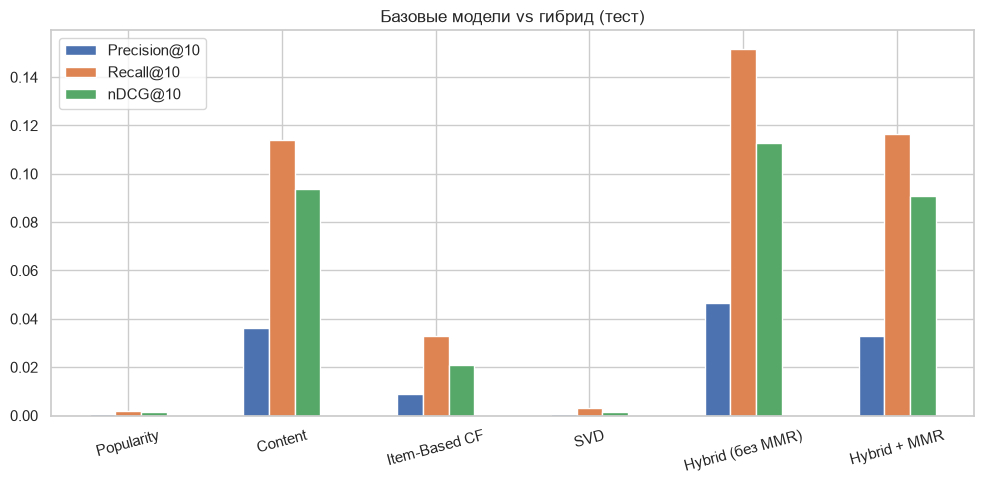

Размеры сегментов на тесте: новые=454, активные=296


,Precision@10,Recall@10,nDCG@10
Новые/малоданные | Item-Based CF,0.0077,0.0445,0.0248
Новые/малоданные | SVD,0.0004,0.0044,0.0021
Новые/малоданные | Hybrid + MMR,0.0260,0.1485,0.1029
Активные | Item-Based CF,0.0105,0.0147,0.0146
Активные | SVD,0.0007,0.0009,0.0008
Активные | Hybrid + MMR,0.0436,0.0670,0.0724


In [8]:
ax = summary.plot(kind='bar', rot=15)
ax.set_title('Базовые модели vs гибрид (тест)')
ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

# анализ по сегментам
test_new = [u for u in test_users if seg_of[u] == 'новый/малоданный']
test_act = [u for u in test_users if seg_of[u] == 'активный']
seg_rows = {}
for seg_name, seg_users in [('Новые/малоданные', test_new), ('Активные', test_act)]:
    for model in ('Item-Based CF', 'SVD', 'Hybrid + MMR'):
        scorer = models_eval['Hybrid (без MMR)'] if model == 'Hybrid + MMR' else models_eval[model]
        seg_rows[f'{seg_name} | {model}'] = evaluate(seg_users, scorer, use_mmr=(model == 'Hybrid + MMR'))
seg_summary = pd.DataFrame(seg_rows, index=['Precision@10', 'Recall@10', 'nDCG@10']).T
print(f'Размеры сегментов на тесте: новые={len(test_new)}, активные={len(test_act)}')
seg_summary.round(4)

## Продвинутая часть. Two-Tower нейросетевая модель

Две башни: эмбеддинг пользователя и эмбеддинг книги, каждая — с MLP поверх.
Обучение на неявном фидбэке (оценка ≥ 4) с **BPR-лоссом**: скор позитивной книги
должен быть выше скора случайной негативной. В отличие от SVD из ДЗ №1, модель
обучается именно на **ранжирование**, а не на RMSE.

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
DEVICE = 'cpu'
DIM = 32

class TwoTower(nn.Module):
    def __init__(self, n_users, n_items, dim):
        super().__init__()
        self.user_tower = nn.Sequential(nn.Embedding(n_users, dim), nn.Linear(dim, 64),
                                        nn.ReLU(), nn.Linear(64, dim))
        self.item_tower = nn.Sequential(nn.Embedding(n_items, dim), nn.Linear(dim, 64),
                                        nn.ReLU(), nn.Linear(64, dim))

    def forward(self, users, items):
        u = F.normalize(self.user_tower(users), dim=1)
        i = F.normalize(self.item_tower(items), dim=1)
        return (u * i).sum(dim=1)

pos_u = train.loc[train.rating >= 4, 'user_id'].map(uid_map).values
pos_i = train.loc[train.rating >= 4, 'book_id'].map(bid_map).values
print(f'Позитивных пар: {len(pos_u):,}')

model = TwoTower(N_USERS, N_BOOKS, DIM).to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=5e-3)
BATCH, EPOCHS = 4096, 15
n_pos = len(pos_u)

t0 = time.time()
for epoch in range(EPOCHS):
    order = np.random.permutation(n_pos)
    total_loss = 0.0
    for start in range(0, n_pos, BATCH):
        idx = order[start:start + BATCH]
        u = torch.tensor(pos_u[idx])
        i_pos = torch.tensor(pos_i[idx])
        i_neg = torch.tensor(np.random.randint(0, N_BOOKS, len(idx)))
        s_pos = model(u, i_pos)
        s_neg = model(u, i_neg)
        loss = -F.logsigmoid(s_pos - s_neg).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        total_loss += loss.item() * len(idx)
    print(f'epoch {epoch + 1}: BPR loss = {total_loss / n_pos:.4f}')
print(f'Обучение Two-Tower: {time.time() - t0:.0f} с')

model.eval()
with torch.no_grad():
    item_embs = F.normalize(model.item_tower(torch.arange(N_BOOKS)), dim=1)
    user_embs = F.normalize(model.user_tower(torch.tensor(eval_inner)), dim=1)
    nn_eval_scores = (user_embs @ item_embs.T).numpy().astype(np.float32)
print('Скоры Two-Tower для eval-пользователей рассчитаны.')

Позитивных пар: 527,359


epoch 1: BPR loss = 0.6936


epoch 2: BPR loss = 0.6923


epoch 3: BPR loss = 0.6876


epoch 4: BPR loss = 0.6674


epoch 5: BPR loss = 0.6228


... (6 outputs left out)

epoch 12: BPR loss = 0.4701


epoch 13: BPR loss = 0.4648


epoch 14: BPR loss = 0.4599


epoch 15: BPR loss = 0.4563
Обучение Two-Tower: 72 с
Скоры Two-Tower для eval-пользователей рассчитаны.


In [10]:
# Two-Tower как отдельная модель: топ-10 по всем книгам с фильтром прочитанного
def evaluate_nn(users, users_set, extra_weight=None):
    metrics = []
    for u, sc_full in zip(eval_users, nn_eval_scores):
        if u not in users_set:
            continue
        if extra_weight is None:
            seen = R[uid_map[u]].indices
            sc = sc_full.copy(); sc[seen] = -np.inf
            recs = np.argpartition(sc, -K_EVAL)[-K_EVAL:]
        else:
            pool, normed = cache[u]
            v = sc_full[pool].astype(np.float64)
            lo, hi = v.min(), v.max()
            nn_norm = (v - lo) / (hi - lo) if hi > lo else np.zeros_like(v)
            base_w = w_new if seg_of[u] == 'новый/малоданный' else w_act
            base = hybrid_rank(pool, normed, base_w)
            score = (1 - extra_weight) * base + extra_weight * nn_norm
            recs = mmr_rerank(pool, score, K_EVAL)
        relevant = {bid_map[b] for b in relevant_by_user[u] if b in bid_map}
        metrics.append(precision_recall_ndcg(recs, relevant, K_EVAL))
    return np.mean(metrics, axis=0)

test_set = set(test_users)
final_rows = {name: evaluate(test_users, models_eval['Hybrid (без MMR)'],
                             use_mmr=(name == 'Hybrid + MMR'))
              for name in ('Hybrid + MMR',)}
final_rows['Two-Tower'] = evaluate_nn(test_users, test_set)
# подбор веса NN в гибриде на валидации
val_set = set(val_users)
best_w, best_ndcg = 0, -1
for w_nn in (0.1, 0.2, 0.3, 0.5):
    _, _, ndcg = evaluate_nn(val_users, val_set, extra_weight=w_nn)
    print(f'вес NN = {w_nn}: nDCG@10 (val) = {ndcg:.4f}')
    if ndcg > best_ndcg:
        best_w, best_ndcg = w_nn, ndcg
print(f'Выбранный вес NN: {best_w}')
final_rows['Hybrid + MMR + Two-Tower'] = evaluate_nn(test_users, test_set, extra_weight=best_w)

nn_summary = pd.DataFrame(final_rows, index=['Precision@10', 'Recall@10', 'nDCG@10']).T
nn_summary.round(4)

вес NN = 0.1: nDCG@10 (val) = 0.1027


вес NN = 0.2: nDCG@10 (val) = 0.0992


вес NN = 0.3: nDCG@10 (val) = 0.0980


вес NN = 0.5: nDCG@10 (val) = 0.0793
Выбранный вес NN: 0.1


,Precision@10,Recall@10,nDCG@10
Hybrid + MMR,0.0329,0.1164,0.0909
Two-Tower,0.0035,0.0064,0.0057
Hybrid + MMR + Two-Tower,0.0339,0.1147,0.0973


## Сквозной пайплайн

Единый процесс «данные → предобработка → обучение → рекомендации → оценка» оформлен
функцией `run_pipeline`: её можно повторно запустить на новых данных (другой `data_dir`)
или переобучить систему после появления новых оценок.

In [11]:
def run_pipeline(user_id, data_dir='data/', n=5):
    """Сквозной запуск: загрузка -> предобработка -> обучение -> рекомендации -> оценка.

    Порядок этапов зафиксирован ячейками ноутбука:
      1. загрузка данных            — ratings/books/tags/book_tags из data_dir
      2. train_test_split_by_user() — сплит 80/20 по пользователю
      3. расширенные признаки       — user_features, book_features, TF-IDF-профили
      4. обучение моделей           — Popularity, ItemCF, SVD, Two-Tower
      5. генерация рекомендаций     — пул кандидатов + веса сегмента + MMR (эта функция)
      6. оценка качества            — Precision/Recall/nDCG@10 (этап 3)
    Для повторного запуска на новых данных выполняются те же ячейки с другим data_dir.
    """
    weights = w_act if seg_of.get(user_id) == 'активный' else w_new
    return recommend_hybrid(user_id, weights, n=n)

# демонстрация финальной выдачи для пользователя из активного сегмента
demo_active = int(test_act[0])
print(f'Пользователь {demo_active} (сегмент: {seg_of[demo_active]}):')
run_pipeline(demo_active)

Пользователь 27489 (сегмент: активный):


,book_id,original_title,authors
0,2019,The Maze of Bones,Rick Riordan
1,7050,Playing with Fire,Derek Landy
2,8106,The Invaders,John Flanagan
3,1043,Rodrick Rules,Jeff Kinney
4,6749,This Book Is Not Good for You,"Pseudonymous Bosch, Gilbert Ford"


## Выводы

1. **Гибридная система оказалась лучше каждой модели по отдельности.** nDCG@10 гибрида (~0.11)
  выше, чем у лучшей отдельной модели — контентной (~0.09). Веса подбирались по nDCG
  на валидации; оптимум для обоих сегментов совпал: основной вклад дают контентная модель
  и ItemCF, популярность берётся с небольшим весом, а SVD в топ-N бесполезна (вес 0).
2. **Контентная модель — неожиданно сильнейшая одиночная.** Профиль «название + теги»
  хорошо угадывает продолжения серий и похожие по жанру книги — именно они часто оказываются
  в тесте пользователя. Это также объясняет её пользу для новых/малоданных пользователей.
3. **Сегментный анализ:** у новых/малоданных пользователей гибрид выигрывает у CF в разы
  (Recall@10 ~0.15 против ~0.04); у активных разница меньше — там история сама по себе
  информативна, а тест «плотнее».
4. **MMR — компромисс между разнообразием и точностью.** Переранжирование убирает
  дублирование похожих книг (одной серии/жанра), но снижает Precision/Recall/nDCG:
  для метрик лучше версия без MMR, для пользовательского опыта — с ним, вес λ стоит
  подбирать отдельно под бизнес-цель.
5. **Two-Tower с BPR-лоссом** обучается (лосс падает от ~0.69 к ~0.5), но за 15 эпох
  на разреженных данных самостоятельно пока слабее классики; добавление её скора в гибрид
  с малым весом (0.1) улучшает nDCG@10 с ~0.091 до ~0.097. Основной потенциал модели —
  в подаче признаков этапа 1 в башни и в масштабировании на больших данных.
6. **Дальше:** признаки в башни Two-Tower (Wide & Deep), hard negative mining,
  больше эпох и регуляризация, sequential-модели (SASRec), онлайн-A/B-тест.